In [5]:
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.config import Config
from aml.gnn import build_snapshots, neighbourhood
from aml.metrics import at_threshold, paired_bootstrap, recall_at_fpr
from aml.pipeline import run_gnn
from aml.plotting import LAUNDERING, MUTED, NORMAL, save, set_style

config = Config()
paths = config.paths
FIG = paths.figures_dir
PROC = paths.processed_dir
REPORTS = paths.reports_dir
SERIES = {"baseline (step 3)": MUTED, "XGBoost + graph features (step 4)": "#1baf7a",
          "GraphSAGE": NORMAL, "no message passing": "#9b59b6", "ensemble (GraphSAGE + step 4)": LAUNDERING}

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("torch", torch.__version__, "| threads", torch.get_num_threads())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
torch 2.5.1+cpu | threads 6


In [6]:
RETRAIN = False   # True: train all three models here (about an hour on a laptop CPU)

metrics_path = REPORTS / "metrics_step5_gnn.json"
if RETRAIN or not metrics_path.exists():
    run_gnn(config)

report = json.loads(metrics_path.read_text())
step3 = json.loads((REPORTS / "metrics_step3_baseline.json").read_text())
step4 = json.loads((REPORTS / "metrics_step4_graph.json").read_text())

gnn_scores = pd.read_parquet(PROC / "gnn_scores.parquet")
base_scores = pd.read_parquet(PROC / "baseline_scores.parquet")
graph_scores = pd.read_parquet(PROC / "graph_scores.parquet")
test = gnn_scores[gnn_scores["split"] == "test"].reset_index(drop=True)
assert (test["tx_id"].to_numpy() == graph_scores.loc[graph_scores["split"] == "test", "tx_id"].to_numpy()).all()
assert (test["tx_id"].to_numpy() == base_scores.loc[base_scores["split"] == "test", "tx_id"].to_numpy()).all()

y_test = test["is_laundering"].to_numpy()
scores = {
    "baseline (step 3)": base_scores.loc[base_scores["split"] == "test", "score"].to_numpy(),
    "XGBoost + graph features (step 4)": graph_scores.loc[graph_scores["split"] == "test", "score"].to_numpy(),
    "GraphSAGE": test["score_gnn"].to_numpy(),
    "no message passing": test["score_no_message_passing"].to_numpy(),
    "ensemble (GraphSAGE + step 4)": test["score_ensemble"].to_numpy(),
}
records = {"baseline (step 3)": step3, "XGBoost + graph features (step 4)": step4,
           "GraphSAGE": report["gnn"], "no message passing": report["no_message_passing"],
           "ensemble (GraphSAGE + step 4)": report["ensemble"]}
print(f"Test set: {len(y_test):,} transactions, {int(y_test.sum()):,} laundering")

Test set: 1,015,751 transactions, 1,143 laundering


## The graph 



In [7]:
tx = pd.read_parquet(PROC / "transactions.parquet",
                     columns=["tx_id", "timestamp", "from_idx", "to_idx", "amount_paid_usd", "is_self_loop"])
hubs = np.array(json.loads((PROC / "graph_feature_list.json").read_text())["hubs"])
day0 = tx["timestamp"].min().normalize()
n_days = int((tx["timestamp"].max().normalize() - day0) / pd.Timedelta(days=1)) + 1
snaps = build_snapshots(tx, hubs, n_days)
snapshot_table = pd.DataFrame({
    "day": [(day0 + pd.Timedelta(days=k)).date() for k in range(n_days)],
    "message_edges": [s.edge_index.shape[1] for s in snaps],
    "accounts_with_history": [int((s.x[:, -1] > 0).sum()) for s in snaps],
})
snapshot_table

16:51:43 | INFO | aml.gnn | snapshot day 0: 0 edges, 0 active accounts
16:51:44 | INFO | aml.gnn | snapshot day 1: 284,012 edges, 437,073 active accounts
16:51:46 | INFO | aml.gnn | snapshot day 2: 454,766 edges, 509,993 active accounts
16:51:48 | INFO | aml.gnn | snapshot day 3: 476,743 edges, 510,772 active accounts
16:51:50 | INFO | aml.gnn | snapshot day 4: 497,599 edges, 511,548 active accounts
16:51:52 | INFO | aml.gnn | snapshot day 5: 517,779 edges, 512,312 active accounts
16:51:54 | INFO | aml.gnn | snapshot day 6: 536,786 edges, 512,907 active accounts
16:51:56 | INFO | aml.gnn | snapshot day 7: 556,033 edges, 513,512 active accounts
16:51:58 | INFO | aml.gnn | snapshot day 8: 574,518 edges, 514,022 active accounts
16:51:59 | INFO | aml.gnn | snapshot day 9: 592,375 edges, 514,561 active accounts


,day,message_edges,accounts_with_history
0,2022-09-01,0,0
1,2022-09-02,284012,437073
2,2022-09-03,454766,509993
3,2022-09-04,476743,510772
4,2022-09-05,497599,511548
5,2022-09-06,517779,512312
6,2022-09-07,536786,512907
7,2022-09-08,556033,513512
8,2022-09-09,574518,514022
9,2022-09-10,592375,514561


In [8]:

rng = np.random.default_rng(0)
last = snaps[-1]
sizes = []
for _ in range(20):
    rows = rng.choice(len(tx), config.gnn.chunk_rows, replace=False)
    nodes = torch.from_numpy(np.concatenate([tx["from_idx"].to_numpy()[rows], tx["to_idx"].to_numpy()[rows]]))
    sub, _ = neighbourhood(last, nodes, config.gnn.layers)
    sizes.append({"accounts": sub.x.shape[0], "edges": sub.edge_index.shape[1]})
sizes = pd.DataFrame(sizes)
print(f"A batch touches {sizes['accounts'].median():,.0f} accounts and {sizes['edges'].median():,.0f} edges "
      f"(median of 20 batches) out of {last.x.shape[0]:,} accounts and {last.edge_index.shape[1]:,} edges")
del tx

A batch touches 70,348 accounts and 99,715 edges (median of 20 batches) out of 515,078 accounts and 592,375 edges


## 3. Training curves



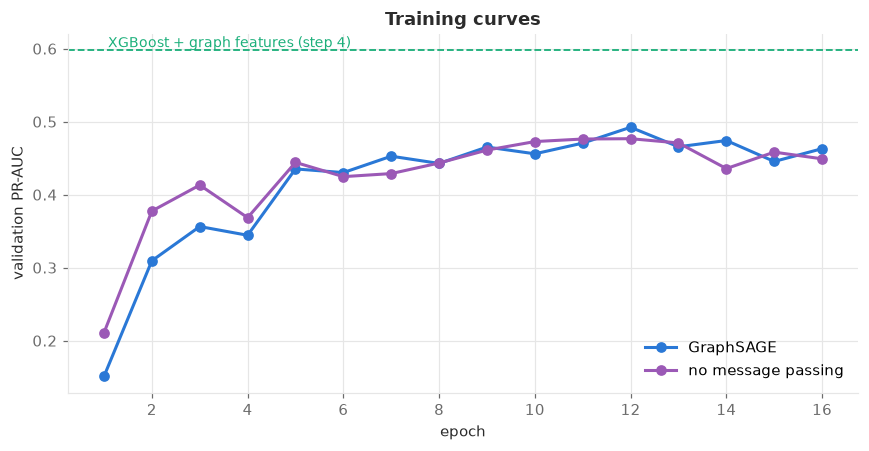

,epochs_run,best_val_pr_auc,minutes
gnn,16.0000,0.4923,13.0191
no_message_passing,16.0000,0.4767,0.9754


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for key, label in [("gnn", "GraphSAGE"), ("no_message_passing", "no message passing")]:
    h = pd.DataFrame(report[key]["search"]).set_index("epoch")
    ax.plot(h.index, h["val_pr_auc"], marker="o", color=SERIES[label], label=label)
ax.axhline(step4["validation"]["pr_auc"], color=SERIES["XGBoost + graph features (step 4)"], linestyle="--",
           linewidth=1.2)
ax.text(1, step4["validation"]["pr_auc"], " XGBoost + graph features (step 4)", va="bottom", fontsize=9,
        color=SERIES["XGBoost + graph features (step 4)"])
ax.set_xlabel("epoch")
ax.set_ylabel("validation PR-AUC")
ax.set_title("Training curves")
ax.legend(loc="lower right")
plt.tight_layout()
save(fig, FIG, "11_gnn_training_curves")
plt.show()

epochs = pd.DataFrame({key: {"epochs_run": len(report[key]["search"]),
                             "best_val_pr_auc": max(r["val_pr_auc"] for r in report[key]["search"]),
                             "minutes": sum(r["minutes"] for r in report[key]["search"])}
                       for key in ["gnn", "no_message_passing"]}).T
epochs

## 4. Comparison on the test set


In [10]:
rows = {}
for name, s in scores.items():
    r = records[name]
    t, fmt = r["test"], r["test_by_format"]
    rows[name] = {
        "PR-AUC": t["pr_auc"], "ROC-AUC": t["roc_auc"],
        "recall at equal FPR (1%)": recall_at_fpr(y_test, s, 0.01),
        "alerts at val threshold": t["alerts_at_1pct"],
        "recall at val threshold": t["recall_at_1pct"],
        "precision at val threshold": t["precision_at_1pct"],
        "PR-AUC within ACH": fmt["ACH only"]["pr_auc"],
        "PR-AUC other formats": fmt["all other formats"]["pr_auc"],
    }
comparison = pd.DataFrame(rows).T
comparison

,PR-AUC,ROC-AUC,recall at equal FPR (1%),alerts at val threshold,recall at val threshold,precision at val threshold,PR-AUC within ACH,PR-AUC other formats
baseline (step 3),0.5583,0.9868,0.8259,"20,084.0000",0.8478,0.0482,0.6368,0.0016
XGBoost + graph features (step 4),0.5669,0.9872,0.8320,"13,979.0000",0.8381,0.0685,0.6466,0.0015
GraphSAGE,0.4460,0.9863,0.7874,"21,111.0000",0.8504,0.0460,0.5087,0.0022
no message passing,0.4339,0.9862,0.8128,"26,657.0000",0.8609,0.0369,0.4955,0.0031
ensemble (GraphSAGE + step 4),0.5546,0.9883,0.8460,"16,847.0000",0.8626,0.0585,0.6321,0.0024


In [11]:
def gains(key: str, against: str) -> pd.DataFrame:
    g = pd.DataFrame(report[key][against]).T
    g.index = pd.MultiIndex.from_product([[key], g.index])
    return g

vs_step4 = pd.concat([gains(k, "vs_graph_model_test") for k in ["gnn", "no_message_passing", "ensemble"]])
print("Difference vs the step 4 model on test (95% block-bootstrap interval, resampling hours):")
vs_step4

Difference vs the step 4 model on test (95% block-bootstrap interval, resampling hours):


difference     ci_low     ci_high  \
gnn                pr_auc                  -0.1209    -0.1388     -0.0999   
                   recall_at_equal_fpr     -0.0446    -0.0608     -0.0232   
                   recall_at_threshold      0.0122    -0.0009      0.0299   
                   alerts_at_threshold  7,132.0000 5,071.4250  9,782.5750   
no_message_passing pr_auc                  -0.1330    -0.1483     -0.1106   
                   recall_at_equal_fpr     -0.0192    -0.0360      0.0000   
                   recall_at_threshold      0.0227     0.0097      0.0371   
                   alerts_at_threshold 12,678.0000 9,044.3500 17,379.1500   
ensemble           pr_auc                  -0.0123    -0.0273      0.0027   
                   recall_at_equal_fpr      0.0140     0.0016      0.0255   
                   recall_at_threshold      0.0245     0.0148      0.0375   
                   alerts_at_threshold  2,868.0000 2,066.7250  3,782.5750   

                                        share_of_draws_above_0  
gnn                pr_auc                               0.0000  
                   recall_at_equal_fpr                  0.0000  
                   recall_at_threshold                  0.9500  
                   alerts_at_threshold                  1.0000  
no_message_passing pr_auc                               0.0000  
                   recall_at_equal_fpr                  0.0250  
                   recall_at_threshold                  1.0000  
                   alerts_at_threshold                  1.0000  
ensemble           pr_auc                               0.0650  
                   recall_at_equal_fpr                  0.9800  
                   recall_at_threshold                  1.0000  
                   alerts_at_threshold                  1.0000

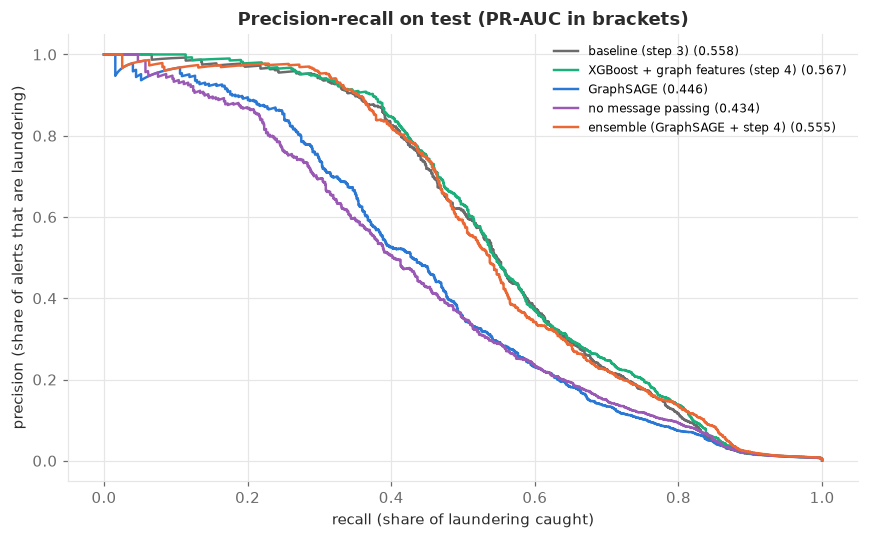

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    ax.plot(r, p, color=SERIES[name], linewidth=1.6, label=f"{name} ({average_precision_score(y_test, s):.3f})")
ax.set_xlabel("recall (share of laundering caught)")
ax.set_ylabel("precision (share of alerts that are laundering)")
ax.set_title("Precision-recall on test (PR-AUC in brackets)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
save(fig, FIG, "12_gnn_vs_trees_pr")
plt.show()

## 5. What message passing adds


In [13]:
hour = pd.read_parquet(PROC / "features.parquet", columns=["tx_id", "timestamp", "split"])
hour = hour[hour["split"] == "test"].reset_index(drop=True)
assert (hour["tx_id"].to_numpy() == test["tx_id"].to_numpy()).all()
hour = hour["timestamp"].dt.floor("h").to_numpy()
thr = {k: report[k]["thresholds_from_val"]["0.01"] for k in ["gnn", "no_message_passing"]}
message_passing_gain = paired_bootstrap(y_test, scores["no message passing"], scores["GraphSAGE"], hour,
                                        thr["no_message_passing"], thr["gnn"],
                                        n_boot=config.graph.n_bootstrap, seed=config.baseline.seed)
message_passing_gain

,difference,ci_low,ci_high,share_of_draws_above_0
pr_auc,0.0121,0.0010,0.0272,0.9850
recall_at_equal_fpr,-0.0254,-0.0381,-0.0106,0.0000
recall_at_threshold,-0.0105,-0.0184,-0.0017,0.0050
alerts_at_threshold,"-5,546.0000","-7,650.2250","-3,972.6500",0.0000


## 6. Model disagreements



In [14]:
fmt_codes = json.loads((PROC / "payment_formats.json").read_text())
names = {v: k for k, v in fmt_codes.items()}
fmt = pd.read_parquet(PROC / "features.parquet", columns=["tx_id", "split", "payment_format_code"])
fmt = fmt[fmt["split"] == "test"]["payment_format_code"].map(names).to_numpy()

flag_tree = scores["XGBoost + graph features (step 4)"] >= step4["thresholds_from_val"]["0.01"]
flag_gnn = scores["GraphSAGE"] >= thr["gnn"]
laund = y_test == 1
overlap = pd.DataFrame({
    "both": (flag_tree & flag_gnn)[laund], "step 4 only": (flag_tree & ~flag_gnn)[laund],
    "GraphSAGE only": (~flag_tree & flag_gnn)[laund], "neither": (~flag_tree & ~flag_gnn)[laund],
    "format": fmt[laund],
}).groupby("format").sum()
overlap.loc["total"] = overlap.sum()
overlap

,both,step 4 only,GraphSAGE only,neither
format,,,,
ACH,933,25,32,9
Bitcoin,0,0,3,10
Cash,0,0,0,22
Cheque,0,0,2,69
Credit Card,0,0,2,36
total,933,25,39,146


## 7. Findings

In [15]:
c = comparison
g4, gg, ge = (c.loc["XGBoost + graph features (step 4)"], c.loc["GraphSAGE"], c.loc["ensemble (GraphSAGE + step 4)"])
d_gnn = vs_step4.loc[("gnn", "pr_auc")]
d_ens = vs_step4.loc[("ensemble", "pr_auc")]
mp = message_passing_gain.loc["pr_auc"]


def verdict(d):
    if d["ci_low"] > 0:
        return "better"
    if d["ci_high"] < 0:
        return "worse"
    return "not distinguishable"


tot = overlap.loc["total"]
lines = [
    f"- **GraphSAGE alone: test PR-AUC {gg['PR-AUC']:.3f}** vs {g4['PR-AUC']:.3f} for the step 4 XGBoost "
    f"(difference {d_gnn['difference']:+.3f}, interval {d_gnn['ci_low']:+.3f} to {d_gnn['ci_high']:+.3f}): "
    f"**{verdict(d_gnn)}**.",
    f"- **Message passing adds {mp['difference']:+.3f} PR-AUC** over the same network without it "
    f"(interval {mp['ci_low']:+.3f} to {mp['ci_high']:+.3f}): {verdict(mp)}.",
    f"- **Ensemble of GraphSAGE and step 4: PR-AUC {ge['PR-AUC']:.3f}** "
    f"(vs step 4 {d_ens['difference']:+.3f}, interval {d_ens['ci_low']:+.3f} to {d_ens['ci_high']:+.3f}: "
    f"{verdict(d_ens)}); recall at equal FPR {ge['recall at equal FPR (1%)']:.1%} vs "
    f"{g4['recall at equal FPR (1%)']:.1%}.",
    f"- **Overlap at the 1% budget**: of {int(y_test.sum())} test laundering transactions, {int(tot['both'])} are caught "
    f"by both, {int(tot['step 4 only'])} only by step 4, {int(tot['GraphSAGE only'])} only by GraphSAGE and "
    f"{int(tot['neither'])} by neither.",
    f"- **Other formats are still out of reach**: PR-AUC {gg['PR-AUC other formats']:.4f} for GraphSAGE, "
    f"as step 4 predicted: no model sees anything that separates that laundering.",
]
display(Markdown("\n".join(lines)))

- **GraphSAGE alone: test PR-AUC 0.446** vs 0.567 for the step 4 XGBoost (difference -0.121, interval -0.139 to -0.100): **worse**.
- **Message passing adds +0.012 PR-AUC** over the same network without it (interval +0.001 to +0.027): better.
- **Ensemble of GraphSAGE and step 4: PR-AUC 0.555** (vs step 4 -0.012, interval -0.027 to +0.003: not distinguishable); recall at equal FPR 84.6% vs 83.2%.
- **Overlap at the 1% budget**: of 1143 test laundering transactions, 933 are caught by both, 25 only by step 4, 39 only by GraphSAGE and 146 by neither.
- **Other formats are still out of reach**: PR-AUC 0.0022 for GraphSAGE, as step 4 predicted: no model sees anything that separates that laundering.